# Hunga Tonga–Hunga Ha'apai: land and vegetation area over time

Part 2 of the Optical Detectors assignment. The notebook

1. measures the land area of the island from the Google Earth (white-light) JPGs with an HSV colour mask,
2. measures the vegetated area from the Sentinel-2 L2A images with an NDVI mask,
3. compares our spectral index with the one from the Sentinel-2 pipeline, and our land areas with an independent Sentinel-2 estimate.

All paths are relative to the repository root. Results are written to `sentinel-processed/`.

# Setting up the imported packages

In [1]:
import csv
import pathlib
import warnings
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, rgb_to_hsv
from scipy import ndimage
import rasterio
from rasterio.errors import NotGeoreferencedWarning
from rasterio.plot import reshape_as_image

In [2]:
%matplotlib inline

# Define all relevant functions

In [3]:
EARTH_RADIUS_M = 6_371_000   # mean Earth radius
FOOTER_ROWS = 60             # Google Earth logo and scale bar at the bottom of every JPG


def read_image(path):
    """
    Read a JPG (or any raster) into an array with rasterio.

    Parameters
    ----------
    path : pathlib.Path
        Image file.

    Returns
    -------
    numpy.ndarray
        Image with shape (bands, rows, cols), e.g. (3, 1992, 2382) for the Google Earth JPGs.
    """
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', NotGeoreferencedWarning)   # the JPGs have no map coordinates
        with rasterio.open(path) as src:
            return src.read()                                    # shape (bands, rows, cols)


def scale_bar_length(rgb, threshold=200, rows=40, x_start=1900):
    """
    Measure the length of the Google Earth scale bar in pixels.

    The bar is the longest run of bright pixels in the bottom-right corner of the image.

    Parameters
    ----------
    rgb : numpy.ndarray
        Image with shape (3, rows, cols).
    threshold : float
        Grey level (0-255) above which a pixel counts as part of the bar.
    rows : int
        Number of rows at the bottom of the image to search.
    x_start : int
        First column of the search region.

    Returns
    -------
    length : int
        Bar length in pixels.
    (x0, x1, y) : tuple of int
        End columns and row of the bar in full-image coordinates (for plotting).
    """
    gray = rgb.mean(axis=0)
    corner = gray[-rows:, x_start:]
    bright = corner > threshold
    row = np.argmax(bright.sum(axis=1))           # the row with the most bright pixels
    cols = np.where(bright[row])[0]

    x0 = x_start + cols.min()                     # convert back to full-image coordinates
    x1 = x_start + cols.max()
    y = gray.shape[0] - rows + row
    return x1 - x0 + 1, (x0, x1, y)


def metres_per_pixel(bar_px, bar_m):
    """
    Pixel size of a JPG from its scale bar.

    Parameters
    ----------
    bar_px : int
        Scale bar length in pixels.
    bar_m : float
        Scale bar length in metres (the label under the bar).

    Returns
    -------
    float
        Metres per pixel (the same in x and y).
    """
    return bar_m / bar_px


def jpg_date(path):
    """Date of a Google Earth image from its name, e.g. '2014Feb.jpg' -> 2014-02-01."""
    return datetime.strptime(pathlib.Path(path).stem, '%Y%b')


def s2_date(folder):
    """Date of a Sentinel-2 folder from its name, e.g. 'S2_2017-07-12' -> 2017-07-12."""
    return datetime.strptime(pathlib.Path(folder).name[3:], '%Y-%m-%d')


def read_band(folder, name):
    """
    Read one Sentinel-2 product from a date folder.

    Parameters
    ----------
    folder : pathlib.Path
        Date folder, e.g. sentinel-data/S2_2017-07-12.
    name : str
        Product name between 'Sentinel-2_L2A_' and '.tiff', e.g. 'B04_Raw' or 'NDVI'.

    Returns
    -------
    data : numpy.ndarray
        float64 array, (rows, cols) for single bands or (bands, rows, cols) for colour products.
    meta : dict
        'res' (degrees per pixel in x and y), 'bounds' (degrees) and 'profile'
        (rasterio profile, used to write masks with the same georeferencing).
    """
    with rasterio.open(folder / f'Sentinel-2_L2A_{name}.tiff') as src:
        data = src.read().astype(np.float64)
        meta = {'res': src.res, 'bounds': src.bounds, 'profile': src.profile}
    return (data[0] if data.shape[0] == 1 else data), meta


def pixel_size_m(res, bounds):
    """
    Convert the angular pixel size of an EPSG:4326 image into metres.

    One degree of latitude is R * pi / 180 metres everywhere, while one degree of longitude
    shrinks by cos(latitude). The latitude used is the centre of the image.

    Parameters
    ----------
    res : tuple of float
        Pixel size (x, y) in degrees, from src.res.
    bounds : rasterio.coords.BoundingBox
        Image boundaries in degrees, from src.bounds.

    Returns
    -------
    dx, dy : float
        Pixel width (east-west) and height (north-south) in metres.
    """
    latitude = np.deg2rad((bounds.top + bounds.bottom) / 2)
    dx = EARTH_RADIUS_M * np.deg2rad(res[0]) * np.cos(latitude)
    dy = EARTH_RADIUS_M * np.deg2rad(res[1])
    return dx, dy


def normalized_difference(a, b):
    """
    Normalised difference index (a - b) / (a + b), e.g. NDVI = (B08 - B04) / (B08 + B04).

    Parameters
    ----------
    a, b : numpy.ndarray
        Reflectance bands with the same shape.

    Returns
    -------
    numpy.ndarray
        Index between -1 and 1, NaN where a + b = 0 (e.g. no-data pixels).
    """
    a = a.astype(np.float64)
    b = b.astype(np.float64)
    total = a + b
    with np.errstate(invalid='ignore', divide='ignore'):
        index = (a - b) / total
    index[total == 0] = np.nan
    return index


def read_ndvi(folder):
    """
    NDVI = (B08 - B04) / (B08 + B04) of one Sentinel-2 date folder.

    Returns
    -------
    ndvi : numpy.ndarray
        NDVI values (-1 to 1, NaN for no data), shape (rows, cols).
    meta : dict
        Metadata of the B04 band (see read_band).
    """
    red, meta = read_band(folder, 'B04_Raw')
    nir, _ = read_band(folder, 'B08_Raw')
    return normalized_difference(nir, red), meta


def remove_small_regions(mask, min_size):
    """
    Remove connected True regions smaller than min_size pixels from a boolean mask.

    Parameters
    ----------
    mask : numpy.ndarray of bool
        Mask to clean.
    min_size : int
        Smallest region (in pixels) that is kept.

    Returns
    -------
    numpy.ndarray of bool
        The mask with only the regions of at least min_size pixels.
    """
    regions, _ = ndimage.label(mask)
    sizes = np.bincount(regions.ravel())
    sizes[0] = 0                                    # label 0 is the background
    return (sizes >= min_size)[regions]


def area_from_mask(mask, pixel_area):
    """
    Area covered by a boolean mask.

    Parameters
    ----------
    mask : numpy.ndarray of bool
        True for the pixels to count.
    pixel_area : float
        Area of one pixel in m².

    Returns
    -------
    float
        Area in m².
    """
    return np.count_nonzero(mask) * pixel_area


def save_mask(mask, path, profile=None):
    """
    Save a boolean mask as 0/1.

    Parameters
    ----------
    mask : numpy.ndarray of bool
        Mask to save.
    path : pathlib.Path
        Output file. Use '.tif' together with `profile`, '.png' otherwise.
    profile : dict, optional
        rasterio profile of the source image. If given, the mask is written as a GeoTIFF with
        the same georeferencing; if not (the JPGs), it is written as a PNG.
    """
    path = pathlib.Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if profile is None:
        plt.imsave(path, mask.astype(np.uint8), cmap='gray', vmin=0, vmax=1)
        return
    profile = {key: value for key, value in profile.items() if key != 'photometric'}
    profile.update(driver='GTiff', count=1, dtype='uint8', nodata=None)
    with rasterio.open(path, 'w', **profile) as dst:
        dst.write(mask.astype(np.uint8), 1)


def land_mask_hsv(rgb, h_range, s_range=(0, 1), v_range=(0, 1), crop_bottom=FOOTER_ROWS,
                  open_iterations=0, min_region=0, max_hole=0):
    """
    Separate land from sea in a Google Earth image using HSV thresholds.

    Parameters
    ----------
    rgb : numpy.ndarray
        Image with shape (3, rows, cols), values 0-255.
    h_range, s_range, v_range : tuple of float
        (min, max) of hue, saturation and value (all 0-1) that count as land. The hue range
        has to be given; saturation and value accept every pixel by default.
    crop_bottom : int
        Rows at the bottom of the image to ignore (Google Earth logo and scale bar).
    open_iterations : int
        Iterations of binary opening, which removes specks and thin lines (waves, sun glint,
        text labels) narrower than about 2 * open_iterations pixels. 0 skips this step.
    min_region : int
        Connected land regions smaller than this many pixels are removed (clouds, shadows,
        leftover specks). 0 keeps every region.
    max_hole : int
        Holes inside the land of at most this many pixels are filled. Larger holes, such as
        the crater lake, stay water. 0 fills no holes.

    Returns
    -------
    numpy.ndarray of bool
        True for land pixels, shape (rows, cols).
    """
    hsv = rgb_to_hsv(reshape_as_image(rgb) / 255)   # shape (rows, cols, 3), values 0-1

    land = np.ones(hsv.shape[:2], dtype=bool)
    for channel, (low, high) in enumerate([h_range, s_range, v_range]):
        land &= (hsv[..., channel] >= low) & (hsv[..., channel] <= high)

    land[-crop_bottom:] = False                     # Google Earth logo and scale bar

    if open_iterations:
        land = ndimage.binary_opening(land, iterations=open_iterations)

    if min_region:
        land = remove_small_regions(land, min_region)

    if max_hole:
        holes, _ = ndimage.label(ndimage.binary_fill_holes(land) & ~land)
        sizes = np.bincount(holes.ravel())
        sizes[0] = 0                                # label 0 is everything that is not a hole
        land = land | ((sizes > 0) & (sizes <= max_hole))[holes]

    return land


def vegetation_mask(ndvi, threshold):
    """
    Vegetation mask from an NDVI image.

    Parameters
    ----------
    ndvi : numpy.ndarray
        NDVI values (-1 to 1, NaN for no data).
    threshold : float
        Pixels with NDVI above this value count as vegetation.

    Returns
    -------
    numpy.ndarray of bool
        True for vegetation (NaN pixels are False).
    """
    return ndvi > threshold


def land_mask_ndwi(ndwi, threshold=0.0, min_region=0):
    """
    Land mask from NDWI = (B03 - B08) / (B03 + B08): water has NDWI > 0, land NDWI < 0.

    Parameters
    ----------
    ndwi : numpy.ndarray
        NDWI values (-1 to 1, NaN for no data).
    threshold : float
        Pixels with NDWI below this value count as land.
    min_region : int
        Connected land regions smaller than this many pixels are removed (e.g. clouds, which
        also have NDWI close to 0). 0 keeps every region.

    Returns
    -------
    numpy.ndarray of bool
        True for land (NaN pixels are False).
    """
    land = ndwi < threshold
    if min_region:
        land = remove_small_regions(land, min_region)
    return land


def pipeline_vegetation_mask(ndvi_rgb):
    """
    Vegetation mask from the Sentinel-2 pipeline NDVI product.

    The pipeline file is a colour visualisation of NDVI (3 bands, 0-1), not the index itself,
    so vegetation has to be recovered from the colours. Its colour scale goes from grey (water)
    through cream and yellow to darker and darker green, and green becomes the strongest channel
    at NDVI of about 0.125. A pixel counts as vegetation where green is the strongest channel,
    so this mask corresponds to a fixed threshold of NDVI >= 0.125.

    Parameters
    ----------
    ndvi_rgb : numpy.ndarray
        Pipeline NDVI image with shape (3, rows, cols).

    Returns
    -------
    numpy.ndarray of bool
        True where green is the strongest colour channel.
    """
    red, green, blue = ndvi_rgb
    return (green > red) & (green > blue)


def compare_masks(mine, theirs):
    """
    Pixel-by-pixel comparison of two boolean masks with the same shape.

    Parameters
    ----------
    mine, theirs : numpy.ndarray of bool
        Our mask and the reference mask.

    Returns
    -------
    dict
        'agreement' (fraction of pixels where both masks agree), 'only_mine' and
        'only_theirs' (pixel counts where only one mask is True) and 'iou'
        (intersection over union of the True pixels).
    """
    both = mine & theirs
    either = mine | theirs
    return {
        'agreement': np.mean(mine == theirs),
        'only_mine': int(np.sum(mine & ~theirs)),
        'only_theirs': int(np.sum(~mine & theirs)),
        'iou': both.sum() / either.sum() if either.any() else np.nan,
    }

# Code execution starts here.

## 0. Define the working directory and inputs
`EXCLUDE` lists the Google Earth images left out of the land-area analysis (see Section 3.4).

In [4]:
here = pathlib.Path('.')
jpg_dir = here / 'sentinel-data' / 'White_light'
s2_dir = here / 'sentinel-data'
out_dir = here / 'sentinel-processed'
out_dir.mkdir(exist_ok=True)

SCALE_BAR_M = 600          # every Google Earth scale bar is labelled 600 m
EXCLUDE = {'2021Dec'}      # eruption plume hides the island

jpg_files = sorted(jpg_dir.glob('*.jpg'), key=jpg_date)
s2_folders = sorted(s2_dir.glob('S2_*'), key=s2_date)

print("Google Earth:", [f.stem for f in jpg_files])
print("Sentinel-2:  ", [f.name for f in s2_folders])

Google Earth: ['2014Feb', '2016May', '2020Nov', '2021Dec', '2022Jan', '2023Oct']
Sentinel-2:   ['S2_2017-07-12', 'S2_2018-07-12', 'S2_2019-07-12']


## 1. Pixel-to-metre ratio of the Google Earth images
Each JPG has a scale bar in the bottom-right corner labelled 600 m. Its length in pixels gives the pixel size,
which is the same in x and y, so the area of one pixel is $(\mathrm{m/px})^2$.

### 1.1. Find the scale bar in one image

310 px from x = 2067 to 2376 at y = 1987


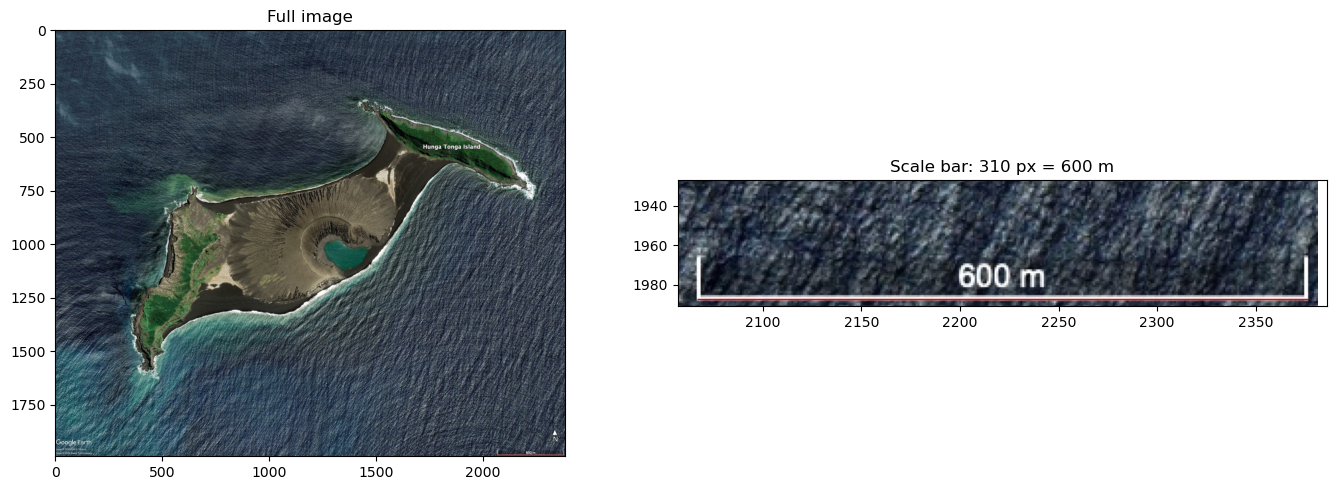

In [5]:
path = jpg_dir / '2020Nov.jpg'
rgb = read_image(path)
length, (x0, x1, y) = scale_bar_length(rgb)
print(f"{length} px from x = {x0} to {x1} at y = {y}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax in axes:
    ax.imshow(reshape_as_image(rgb))
    ax.plot([x0, x1], [y, y], color='red', lw=1)

axes[1].set_xlim(x0 - 10, x1 + 10)
axes[1].set_ylim(rgb.shape[1] - 1, y - 60)        # y increases downwards in image coordinates
axes[0].set_title('Full image')
axes[1].set_title(f'Scale bar: {length} px = {SCALE_BAR_M} m')

plt.tight_layout()
plt.show()

### 1.2. Pixel size of every image

In [6]:
jpg_scale = {}   # image name -> metres per pixel

for file in jpg_files:
    bar_px, _ = scale_bar_length(read_image(file))
    jpg_scale[file.stem] = metres_per_pixel(bar_px, SCALE_BAR_M)
    print(f"{file.stem:8} bar {bar_px:4d} px -> {jpg_scale[file.stem]:.3f} m/px, "
          f"{jpg_scale[file.stem] ** 2:.3f} m² per pixel")

# effect of a bar one pixel shorter or longer
for bar_px in (309, 311):
    pixel_area = metres_per_pixel(bar_px, SCALE_BAR_M) ** 2
    print(f"bar {bar_px} px -> {pixel_area:.3f} m² per pixel "
          f"({pixel_area / metres_per_pixel(310, SCALE_BAR_M) ** 2 - 1:+.2%} vs 310 px)")

2014Feb  bar  310 px -> 1.935 m/px, 3.746 m² per pixel
2016May  bar  310 px -> 1.935 m/px, 3.746 m² per pixel


2020Nov  bar  310 px -> 1.935 m/px, 3.746 m² per pixel
2021Dec  bar  310 px -> 1.935 m/px, 3.746 m² per pixel


2022Jan  bar  310 px -> 1.935 m/px, 3.746 m² per pixel


2023Oct  bar  310 px -> 1.935 m/px, 3.746 m² per pixel
bar 309 px -> 3.770 m² per pixel (+0.65% vs 310 px)
bar 311 px -> 3.722 m² per pixel (-0.64% vs 310 px)


The results show that all bars are the same length, which means the images were exported from Google Earth at the same zoom level and resolution, with only the date changed.

The measurement of the number of pixels in the bar is quite precise (see figure above). Even if the bar were a pixel longer or shorter, the area per pixel would change by less than 1% (a bar of 309 pixels gives 3.770 m² per pixel and one of 311 gives 3.722 m², against 3.746 m² for 310). This variation is not significant enough to affect our results.

## 2. Pixel-to-metre ratio of the Sentinel-2 images
The Sentinel-2 products are in EPSG:4326, so `src.res` gives the pixel size in degrees. With the latitude $\phi$ at the centre of the image (from `src.bounds`)
and $R_\oplus$ the Earth's radius,

$$\Delta y = R_\oplus\,\Delta\phi, \qquad \Delta x = R_\oplus \cos\phi\,\Delta\lambda,$$

with $\Delta\phi$ and $\Delta\lambda$ in radians. The native resolution of B04 and B08 is 10 m, but the products are resampled onto a grid in degrees, so the pixel size in metres has to be calculated.

In [7]:
s2_pixel_area = {}   # folder name -> m² per pixel

for folder in s2_folders:
    _, meta = read_band(folder, 'B04_Raw')
    dx, dy = pixel_size_m(meta['res'], meta['bounds'])
    s2_pixel_area[folder.name] = dx * dy
    print(f"{folder.name}: res {meta['res'][0]:.3e}° x {meta['res'][1]:.3e}° -> "
          f"{dx:.2f} m x {dy:.2f} m = {dx * dy:.1f} m²")

# numbers quoted below, for the last folder (all three have the same grid)
res, bounds = meta['res'], meta['bounds']
latitude = (bounds.top + bounds.bottom) / 2
cos_lat = np.cos(np.deg2rad(latitude))
print(f"centre latitude {latitude:.2f}°, cos(latitude) = {cos_lat:.4f}, "
      f"latitude step / longitude step = {res[1] / res[0]:.4f}")
print(f"longitude step at the equator: {EARTH_RADIUS_M * np.deg2rad(res[0]):.2f} m")
print(f"assuming 10 m x 10 m pixels would overestimate areas by {100 / (dx * dy) - 1:.1%}")
cos_edges = np.cos(np.deg2rad([bounds.bottom, bounds.top])) / cos_lat - 1
print(f"cos(latitude) at the bottom/top edge differs from the centre by {cos_edges[0]:+.4%} / {cos_edges[1]:+.4%}")

# WGS84 ellipsoid: meridional (M) and prime-vertical (N) radii of curvature at the centre latitude
a, f = 6_378_137.0, 1 / 298.257223563
e2 = f * (2 - f)
sin2 = np.sin(np.deg2rad(latitude)) ** 2
M = a * (1 - e2) / (1 - e2 * sin2) ** 1.5
N = a / np.sqrt(1 - e2 * sin2)
wgs84_area = (N * cos_lat * np.deg2rad(res[0])) * (M * np.deg2rad(res[1]))
print(f"WGS84 pixel area {wgs84_area:.1f} m² ({wgs84_area / (dx * dy) - 1:+.2%} vs the sphere)")

S2_2017-07-12: res 8.989e-05° x 8.413e-05° -> 9.36 m x 9.35 m = 87.6 m²
S2_2018-07-12: res 8.989e-05° x 8.413e-05° -> 9.36 m x 9.35 m = 87.6 m²
S2_2019-07-12: res 8.989e-05° x 8.413e-05° -> 9.36 m x 9.35 m = 87.6 m²
centre latitude -20.54°, cos(latitude) = 0.9364, latitude step / longitude step = 0.9359
longitude step at the equator: 9.99 m
assuming 10 m x 10 m pixels would overestimate areas by 14.2%
cos(latitude) at the bottom/top edge differs from the centre by -0.0086% / +0.0086%
WGS84 pixel area 87.3 m² (-0.28% vs the sphere)


The calculated ground dimensions of the pixels (about 9.36 m × 9.35 m, 87.6 m²) are slightly below the native 10 m resolution. The longitude step (8.989e-5°) corresponds to 10 m at the equator, but at the island's latitude (about 20.6° S) it shrinks by $\cos\phi \approx 0.936$ to 9.36 m. The latitude step (8.413e-5°) is the longitude step multiplied by the same $\cos\phi$, so the pixels are square on the ground. Assuming 10 m pixels would overestimate every area by about 14%.

The variation in latitude across each image is small, so its effect on pixel dimensions is negligible for this analysis. Using a spherical Earth instead of the WGS84 ellipsoid changes the pixel area by only about 0.3%.

## 3. Land area from the Google Earth images (HSV mask)
In HSV space, sea and land separate mainly by hue (blue water vs brown/green land). The mask keeps the pixels inside a hue range
and then cleans the result: a binary opening removes specks and thin lines, connected regions smaller than `min_region` pixels
are removed, and holes up to `max_hole` pixels are filled. The hue range is chosen on 2020Nov and the same settings are applied to every image.

### 3.1. Explore the HSV values of one image

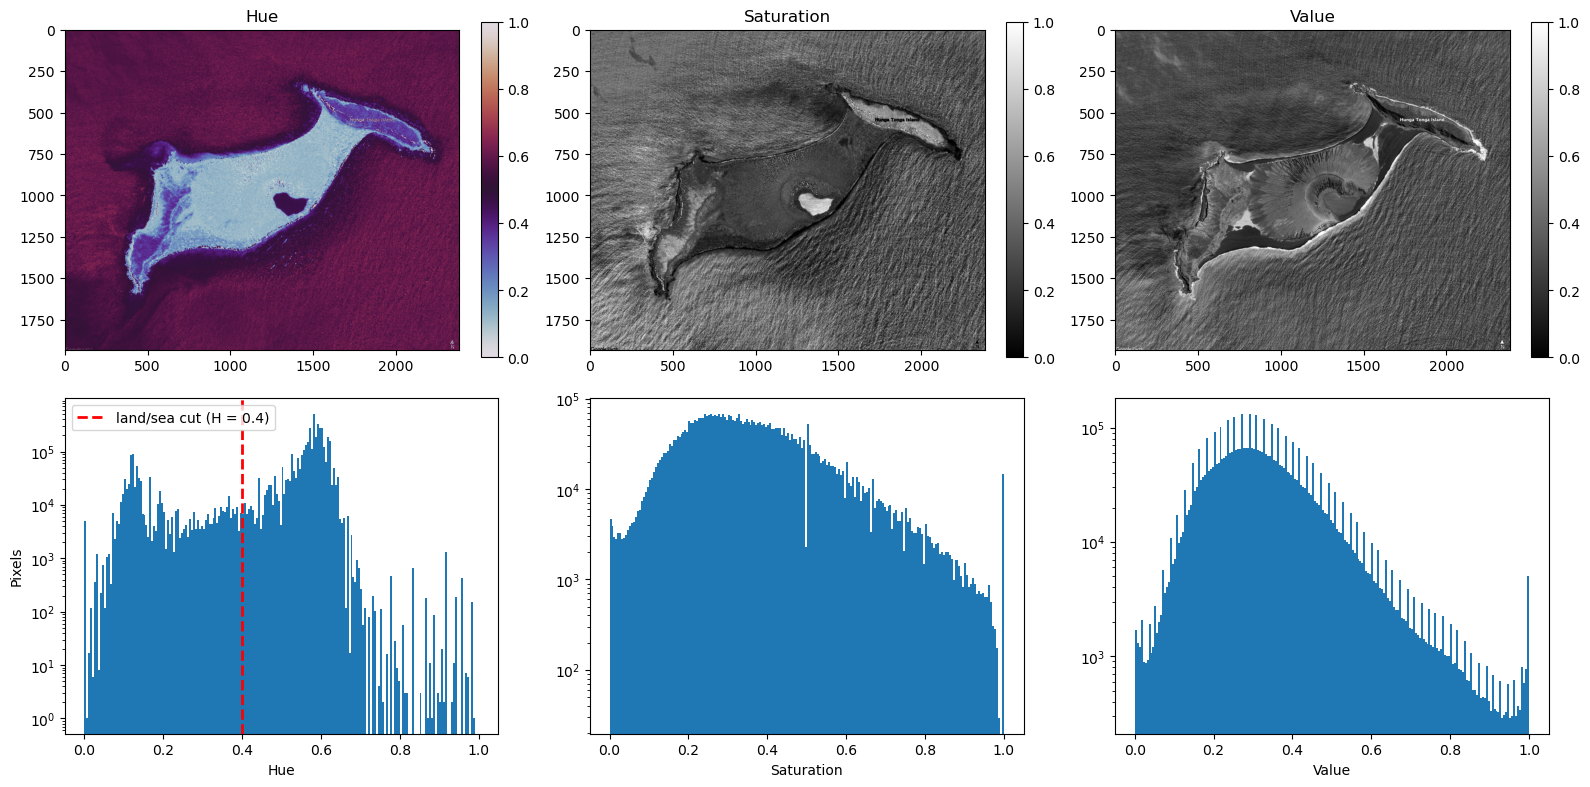

In [8]:
H_RANGE = (0, 0.40)   # hue range that counts as land, used for every image

rgb = read_image(jpg_dir / '2020Nov.jpg')
hsv = rgb_to_hsv(reshape_as_image(rgb) / 255)   # shape (rows, cols, 3), values 0-1
hsv = hsv[:-FOOTER_ROWS]                        # drop the logo and scale bar rows

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, channel, name in zip(axes[0], range(3), ['Hue', 'Saturation', 'Value']):
    im = ax.imshow(hsv[..., channel], cmap='twilight' if channel == 0 else 'gray', vmin=0, vmax=1)
    ax.set_title(name)
    fig.colorbar(im, ax=ax, fraction=0.04)

for ax, channel, name in zip(axes[1], range(3), ['Hue', 'Saturation', 'Value']):
    ax.hist(hsv[..., channel].ravel(), bins=200, range=(0, 1), log=True)
    ax.set_xlabel(name)
axes[1, 0].axvline(H_RANGE[1], color='red', ls='--', lw=2, label=f'land/sea cut (H = {H_RANGE[1]})')
axes[1, 0].legend()
axes[1, 0].set_ylabel('Pixels')

plt.tight_layout()
plt.show()

A hue range between 0 and 0.40 was chosen manually after plotting the image and observing the lowest hue values of the pixels in the sea. This provided us with a first approximation, which was later refined through trial and error, as we plotted the mask and checked whether any significant portions of pixels were mistakenly identified as land.

Grey and white pixels (surf, clouds, sun glint) have no defined hue and are given H = 0, so they also pass the hue cut. These are removed by the cleaning steps in Section 3.2.

### 3.2. Apply the mask to one image

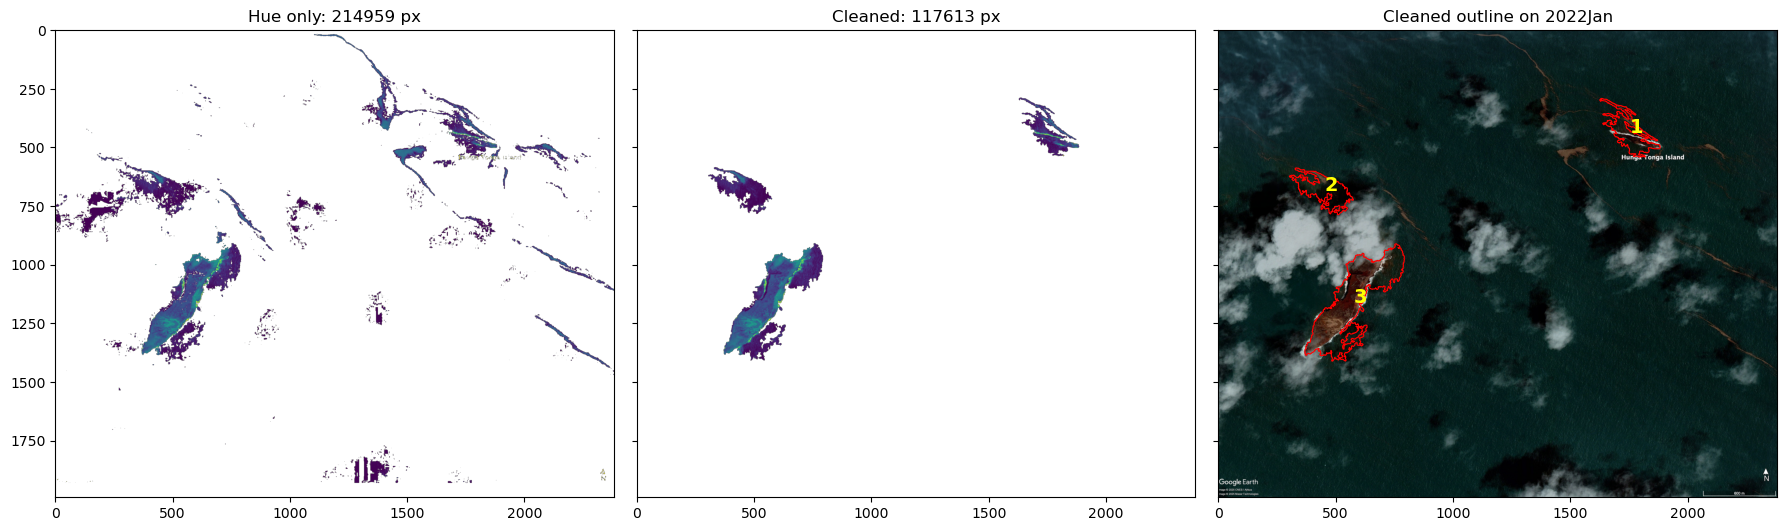

hue only 214959 px, cleaned 117613 px out of 4744944: 101744 px removed, 4398 px filled
region 1:    19330 px = 0.0724 km²
region 2:    21217 px = 0.0795 km²
region 3:    77066 px = 0.2887 km²


largest regions after the opening (min_region = 10000): [73753 20552 18383  9643  7270  5499  4390  3836]


In [9]:
CLEAN = dict(open_iterations=2, min_region=10_000, max_hole=5_000)   # used for every image

EXAMPLE = '2022Jan'
rgb = read_image(jpg_dir / f'{EXAMPLE}.jpg')
raw = land_mask_hsv(rgb, H_RANGE)
land = land_mask_hsv(rgb, H_RANGE, **CLEAN)
image = reshape_as_image(rgb)

regions, n_regions = ndimage.label(land)
region_labels = range(1, n_regions + 1)
sizes = ndimage.sum(land, regions, region_labels)
centres = ndimage.center_of_mass(land, regions, region_labels)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
axes[0].imshow(np.ma.masked_array(image[..., 0], mask=~raw))
axes[0].set_title(f'Hue only: {raw.sum()} px')
axes[1].imshow(np.ma.masked_array(image[..., 0], mask=~land))
axes[1].set_title(f'Cleaned: {land.sum()} px')
axes[2].imshow(image)
axes[2].contour(land, levels=[0.5], colors='red', linewidths=0.8)
for number, (row, col) in zip(region_labels, centres):
    axes[2].annotate(str(number), (col, row), color='yellow', fontsize=14, fontweight='bold')
axes[2].set_title(f'Cleaned outline on {EXAMPLE}')

plt.tight_layout()
plt.show()

change = land.astype(int) - raw.astype(int)
print(f"hue only {raw.sum()} px, cleaned {land.sum()} px out of {land.size}: "
      f"{np.sum(change < 0)} px removed, {np.sum(change > 0)} px filled")
for number, size in zip(region_labels, sizes):
    print(f"region {number}: {size:8.0f} px = {size * jpg_scale[EXAMPLE] ** 2 / 1e6:.4f} km²")

# the regions that min_region compares against: after the opening, before any region is removed
opened = land_mask_hsv(rgb, H_RANGE, open_iterations=CLEAN['open_iterations'])
opened_sizes = np.sort(np.bincount(ndimage.label(opened)[0].ravel())[1:])[::-1]
print(f"largest regions after the opening (min_region = {CLEAN['min_region']}):", opened_sizes[:8])


### 3.3. Land area of every image

In [10]:
land_files = [file for file in jpg_files if file.stem not in EXCLUDE]
land_area = {}   # image name -> land area in m²

for file in land_files:
    rgb = read_image(file)
    land = land_mask_hsv(rgb, H_RANGE, **CLEAN)
    land_area[file.stem] = area_from_mask(land, jpg_scale[file.stem] ** 2)
    save_mask(land, out_dir / f"{file.stem}_land_mask.png")

### 3.4. Excluding 2021Dec
Early on, we noticed that the 2021Dec image shows the entire island covered by a volcanic plume of ash and steam (see figure below). The volcano became active again on 20 December 2021, and this activity culminated in the main eruption of 15 January 2022, less than a month later. Since the land cannot be seen, the HSV mask would measure the plume and not the island, so this image was excluded from the land-area analysis.

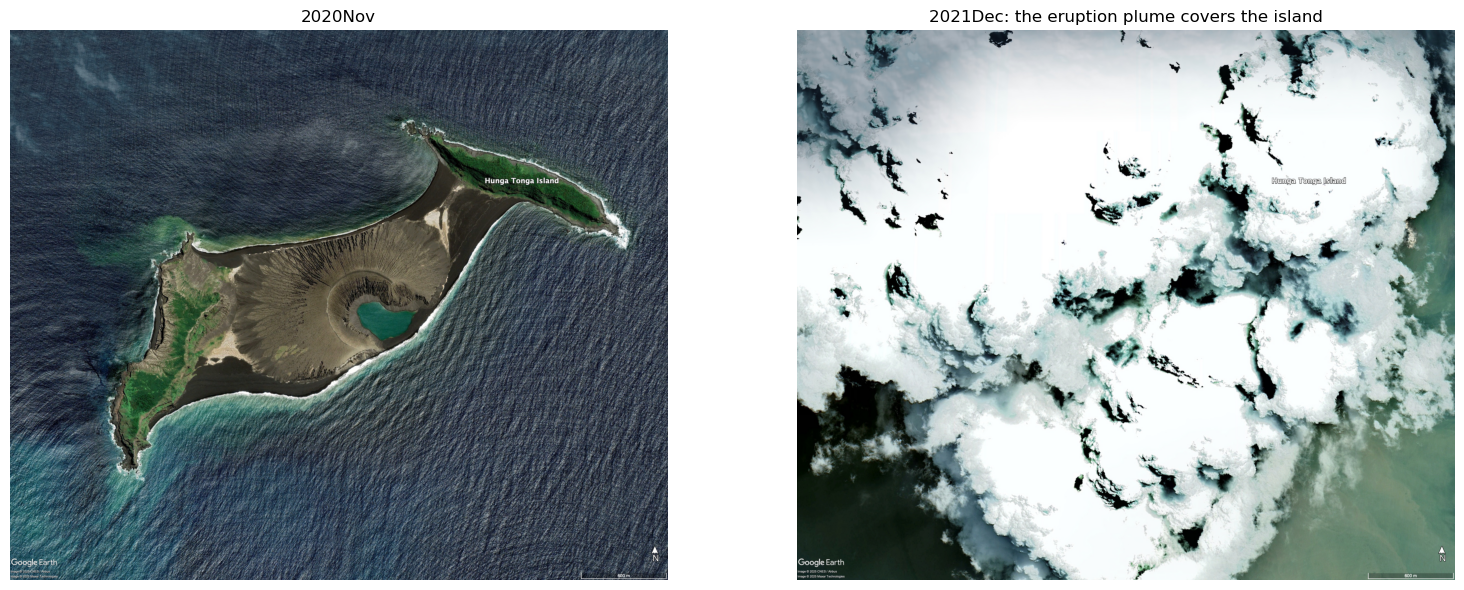

In [11]:
def show_jpg(name, ax=None):
    """Show one Google Earth image by name, e.g. show_jpg('2021Dec')."""
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 6))
    ax.imshow(reshape_as_image(read_image(jpg_dir / f'{name}.jpg')))
    ax.set_title(name)
    ax.axis('off')
    return ax


fig, axes = plt.subplots(1, 2, figsize=(16, 6))
show_jpg('2020Nov', axes[0])
show_jpg('2021Dec', axes[1])
axes[1].set_title('2021Dec: the eruption plume covers the island')
plt.tight_layout()
plt.show()

### 3.5. Land area over time

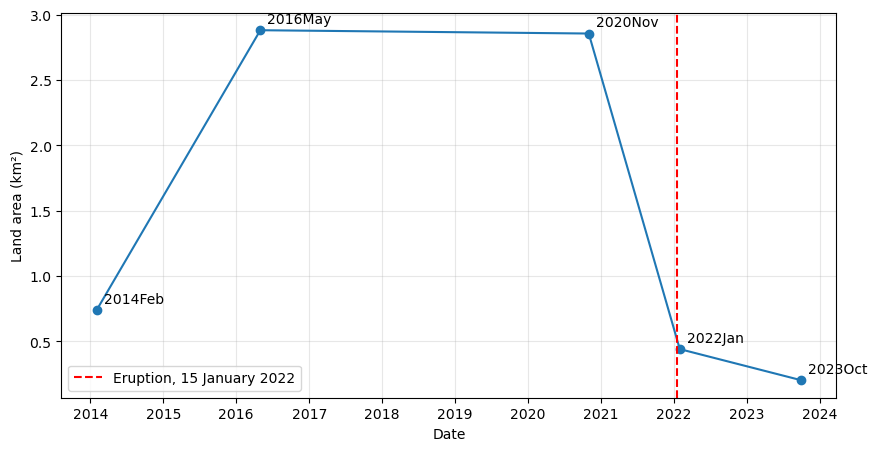

2014Feb: 0.739 km²
2016May: 2.882 km²
2020Nov: 2.856 km²
2022Jan: 0.441 km²
2023Oct: 0.202 km²


In [12]:
ERUPTION = datetime(2022, 1, 15)
names = list(land_area)
# The file names only give the month, so jpg_date() returns the 1st. 2022Jan was taken after the
# eruption (exact day unknown), so it is dated at the end of January instead (also in areas.csv).
jpg_dates = {name: jpg_date(name) for name in names}
jpg_dates['2022Jan'] = datetime(2022, 1, 31)
dates = [jpg_dates[name] for name in names]
areas_km2 = [land_area[name] / 1e6 for name in names]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(dates, areas_km2, 'o-')
for date, area, name in zip(dates, areas_km2, names):
    ax.annotate(name, (date, area), textcoords='offset points', xytext=(5, 5))
ax.axvline(ERUPTION, color='red', ls='--', label='Eruption, 15 January 2022')
ax.set_xlabel('Date')
ax.set_ylabel('Land area (km²)')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

for name, area in zip(names, areas_km2):
    print(f"{name}: {area:.3f} km²")

We can observe that the land area increased greatly between 2014 and 2016, from roughly 0.75 km² to 3 km². During the December 2014 – January 2015 eruption, material from the underwater volcano rose above sea level and formed a new cone between the two separate islands, merging them into a single, larger island. From 2016 to 2020 the total area remained roughly stable, although we have no Google Earth images between these dates. The violent eruption of 15 January 2022 destroyed the central cone and most of the island, and the caldera beneath it collapsed, leaving only small remnants of Hunga Tonga and Hunga Ha'apai above sea level. The land area therefore dropped to around 0.5 km².

From 2022 to 2023 we see a further decrease in the land area. However, this is partly because the 2022Jan mask counts a cloud shadow as land (region 2 in Section 3.2, about 0.0795 km²). The decrease could also be explained due to sequels from the eruption or erosion from the waves over time. If the volcano became inactive after the explosion, it would gradually lose area over time if no other processes took place. 

## 4. Vegetated area from Sentinel-2 (NDVI mask)
NDVI is computed from the bottom-of-atmosphere reflectance of the red (B04) and near-infrared (B08) bands:

$$\mathrm{NDVI} = \frac{B08 - B04}{B08 + B04}.$$

Vegetation reflects strongly in the NIR and absorbs red light, so it has high NDVI. Water is negative and bare rock/ash is close to 0.
The three Sentinel-2 dates (July 2017, 2018 and 2019) are all before the eruption.

### 4.1. NDVI of one date

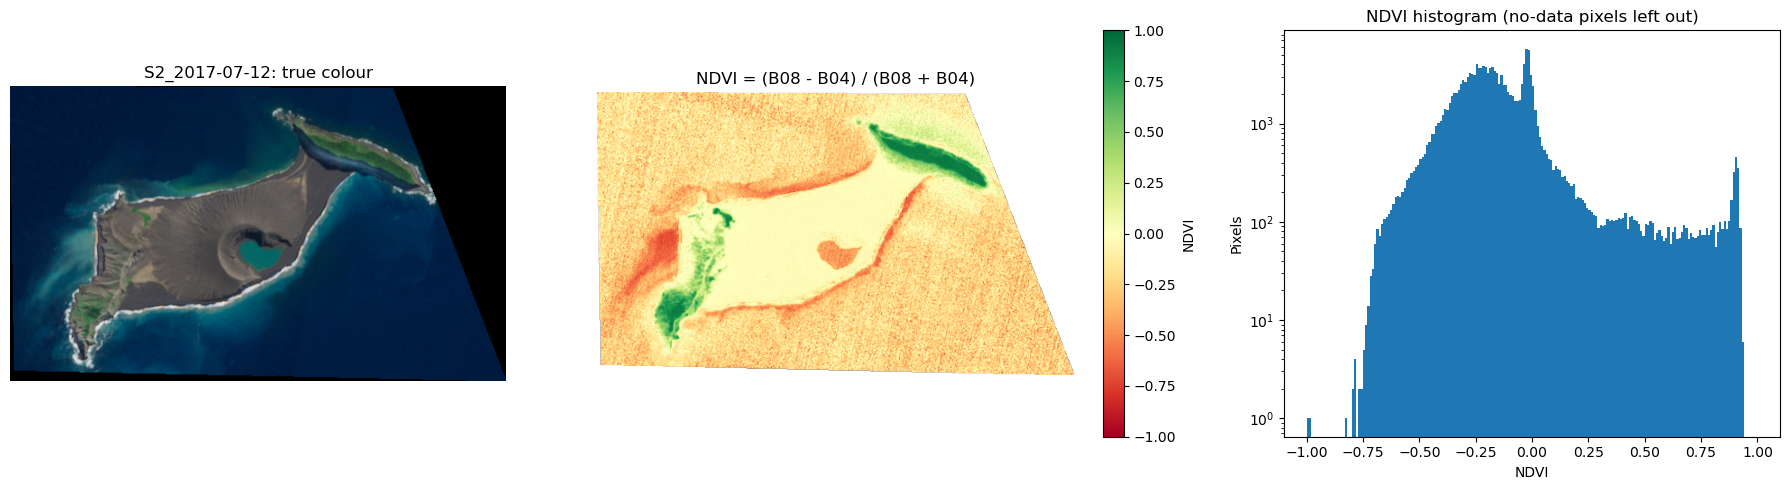

22751 no-data pixels out of 166106


In [13]:
folder = s2_folders[0]
ndvi, meta = read_ndvi(folder)

true_color, _ = read_band(folder, 'True_color')   # shape (3, rows, cols), values 0-1

fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={'width_ratios': [1, 1.2, 1]})
axes[0].imshow(reshape_as_image(true_color))
axes[0].set_title(f'{folder.name}: true colour')
im = axes[1].imshow(ndvi, cmap='RdYlGn', vmin=-1, vmax=1)
fig.colorbar(im, ax=axes[1], label='NDVI')
axes[1].set_title('NDVI = (B08 - B04) / (B08 + B04)')
for ax in axes[:2]:
    ax.axis('off')

axes[2].hist(ndvi[~np.isnan(ndvi)], bins=200, range=(-1, 1), log=True)
axes[2].set_xlabel('NDVI')
axes[2].set_ylabel('Pixels')
axes[2].set_title('NDVI histogram (no-data pixels left out)')

plt.tight_layout()
plt.show()

print(f"{np.isnan(ndvi).sum()} no-data pixels out of {ndvi.size}")

### 4.2. Choosing the NDVI threshold
We chose a threshold of 0.5 manually, after comparing the NDVI image to the true-colour image and zooming in on the less vegetated areas to see what NDVI values they had. Below 0.5, these areas show bare rock and sand with scattered patches of vegetation. This is consistent with typical literature values: bare rock, sand and ash have NDVI of about 0–0.2, sparse vegetation about 0.2–0.5, and dense vegetation above 0.5. A threshold of 0.5 therefore counts only fairly dense vegetation, so the vegetated area is a conservative estimate. Section 5.2 shows how the area depends on this choice.

Note that this is not the same as the threshold of 0.125 in Section 5. That value is not a choice of ours: it is the NDVI at which the pipeline's colour visualisation turns green, and it is only used there to compare our mask with the pipeline's.

In [14]:
NDVI_THRESHOLD = 0.5

### 4.3. Vegetated area of every date

In [15]:
ndvi_by_date = {}   # folder name -> NDVI image, reused in Section 5
veg_area = {}       # folder name -> vegetated area in m²

for folder in s2_folders:
    ndvi, meta = read_ndvi(folder)
    ndvi_by_date[folder.name] = ndvi
    vegetation = vegetation_mask(ndvi, NDVI_THRESHOLD)
    veg_area[folder.name] = area_from_mask(vegetation, s2_pixel_area[folder.name])
    save_mask(vegetation, out_dir / f"{folder.name}_vegetation_mask.tif", meta['profile'])

### 4.4. Vegetated area over time

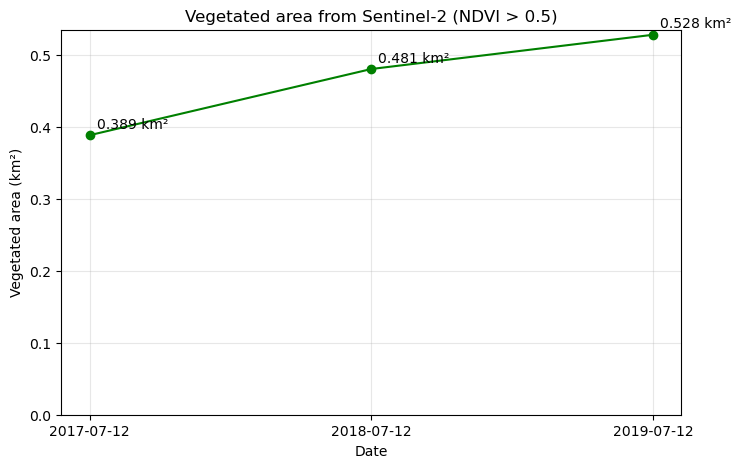

S2_2017-07-12: 0.3887 km²
S2_2018-07-12: 0.4808 km²
S2_2019-07-12: 0.5285 km²
S2_2017-07-12 -> S2_2018-07-12: +23.7%
S2_2018-07-12 -> S2_2019-07-12: +9.9%
S2_2017-07-12 -> S2_2019-07-12: +35.9%


In [16]:
names = list(veg_area)
dates = [s2_date(name) for name in names]
areas_km2 = [veg_area[name] / 1e6 for name in names]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(dates, areas_km2, 'o-', color='green')
for date, area in zip(dates, areas_km2):
    ax.annotate(f'{area:.3f} km²', (date, area), textcoords='offset points', xytext=(5, 5))
ax.set_xticks(dates)
ax.set_xticklabels([date.strftime('%Y-%m-%d') for date in dates])
ax.set_ylim(bottom=0)
ax.set_xlabel('Date')
ax.set_ylabel('Vegetated area (km²)')
ax.set_title(f'Vegetated area from Sentinel-2 (NDVI > {NDVI_THRESHOLD})')
ax.grid(alpha=0.3)
plt.show()

for name, area in zip(names, areas_km2):
    print(f"{name}: {area:.4f} km²")
for name0, name1, area0, area1 in zip(names, names[1:], areas_km2, areas_km2[1:]):
    print(f"{name0} -> {name1}: {area1 / area0 - 1:+.1%}")
print(f"{names[0]} -> {names[-1]}: {areas_km2[-1] / areas_km2[0] - 1:+.1%}")

In this case, we only had Sentinel-2 images from 2017 to 2019, so we studied the evolution of the vegetated area during this period. All three images were taken on 12 July, so seasonal changes in vegetation do not affect the comparison. The vegetated area increases every year, from 0.389 km² in 2017 to 0.481 km² in 2018 and 0.529 km² in 2019, a total increase of about 36%, although the growth slows down in the second year. During this period the volcano was inactive and the island remained stable, allowing plant life to grow and spread across the bare rock and sand of the island.

This serves as an example of Dr. Ian Malcolm's famous saying "life finds a way", as we can see that even on a volcanic island that had only recently changed shape, the total area covered by plants increased over time. 

# Compare and Contrast

## 5. Comparison with the Sentinel-2 pipeline and between data sets
### 5.1. Our NDVI vs the pipeline NDVI
The pipeline `NDVI.tiff` is a 3-band colour visualisation (values 0–1) of the index, not the index itself.
The values cannot be compared directly, so we compare the vegetation masks pixel by pixel and the vegetated areas they give.

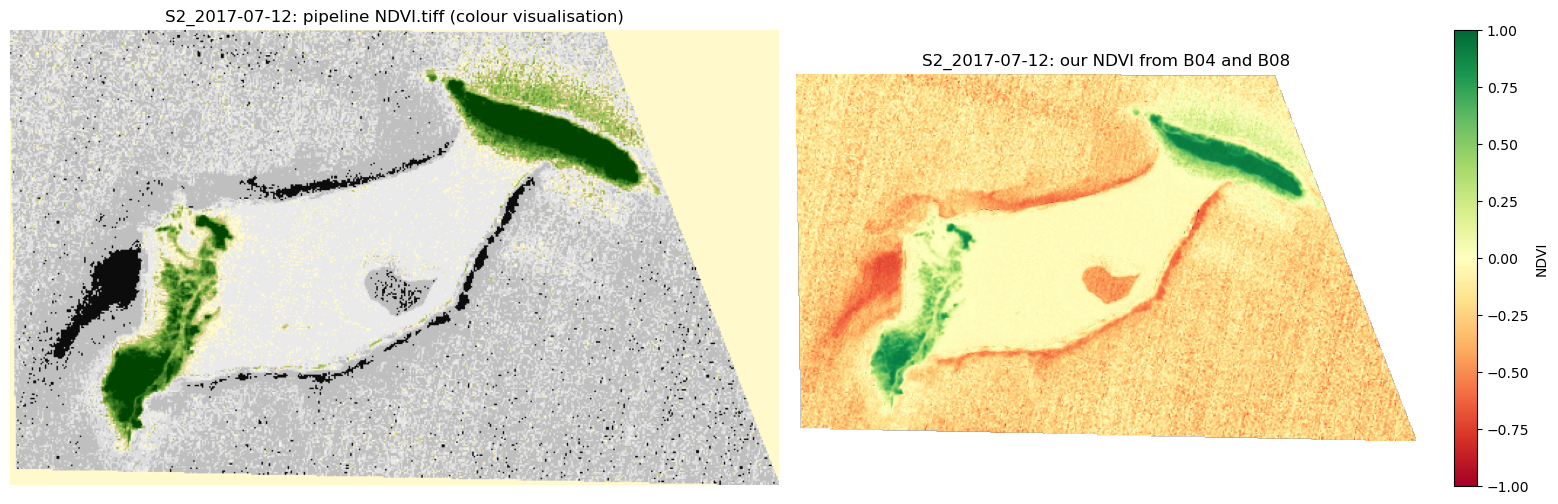

In [17]:
PIPELINE_THRESHOLD = 0.125   # green is the strongest channel from this NDVI step on (see pipeline_vegetation_mask)

folder = s2_folders[0]
pipeline_rgb, _ = read_band(folder, 'NDVI')   # shape (3, rows, cols)
ndvi = ndvi_by_date[folder.name]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].imshow(reshape_as_image(pipeline_rgb))
axes[0].set_title(f'{folder.name}: pipeline NDVI.tiff (colour visualisation)')
im = axes[1].imshow(ndvi, cmap='RdYlGn', vmin=-1, vmax=1)
fig.colorbar(im, ax=axes[1], label='NDVI')
axes[1].set_title(f'{folder.name}: our NDVI from B04 and B08')
for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

In [18]:
pipeline_masks = {}      # folder name -> vegetation mask from the pipeline colours
pipeline_veg_area = {}   # folder name -> vegetated area in m² from the pipeline colours

print(f"{'date':13} {'threshold':>9} {'ours (km²)':>10} {'pipeline (km²)':>14} "
      f"{'ours/pipeline':>13} {'agreement':>9} {'only ours':>9} {'only pipeline':>13} {'IoU':>6}")
for folder in s2_folders:
    ndvi = ndvi_by_date[folder.name]
    pixel_area = s2_pixel_area[folder.name]

    theirs = pipeline_vegetation_mask(read_band(folder, 'NDVI')[0])
    pipeline_masks[folder.name] = theirs
    pipeline_veg_area[folder.name] = area_from_mask(theirs, pixel_area)

    # our mask at our own threshold, and at the threshold the pipeline mask corresponds to
    for threshold in (NDVI_THRESHOLD, PIPELINE_THRESHOLD):
        mine = vegetation_mask(ndvi, threshold)
        result = compare_masks(mine, theirs)
        my_area = area_from_mask(mine, pixel_area)
        print(f"{folder.name:13} {threshold:9.3f} {my_area / 1e6:10.4f} "
              f"{pipeline_veg_area[folder.name] / 1e6:14.4f} {my_area / pipeline_veg_area[folder.name]:13.1%} "
              f"{result['agreement']:9.4f} "
              f"{result['only_mine']:9d} {result['only_theirs']:13d} {result['iou']:6.3f}")

date          threshold ours (km²) pipeline (km²) ours/pipeline agreement only ours only pipeline    IoU
S2_2017-07-12     0.500     0.3887         0.8620         45.1%    0.9675         0          5406  0.451
S2_2017-07-12     0.125     0.8526         0.8620         98.9%    0.9942       426           534  0.907
S2_2018-07-12     0.500     0.4808         0.8809         54.6%    0.9725         2          4571  0.546
S2_2018-07-12     0.125     0.8612         0.8809         97.8%    0.9943       365           590  0.908
S2_2019-07-12     0.500     0.5285         1.0929         48.4%    0.9612         0          6447  0.484
S2_2019-07-12     0.125     1.0746         1.0929         98.3%    0.9921       550           759  0.900


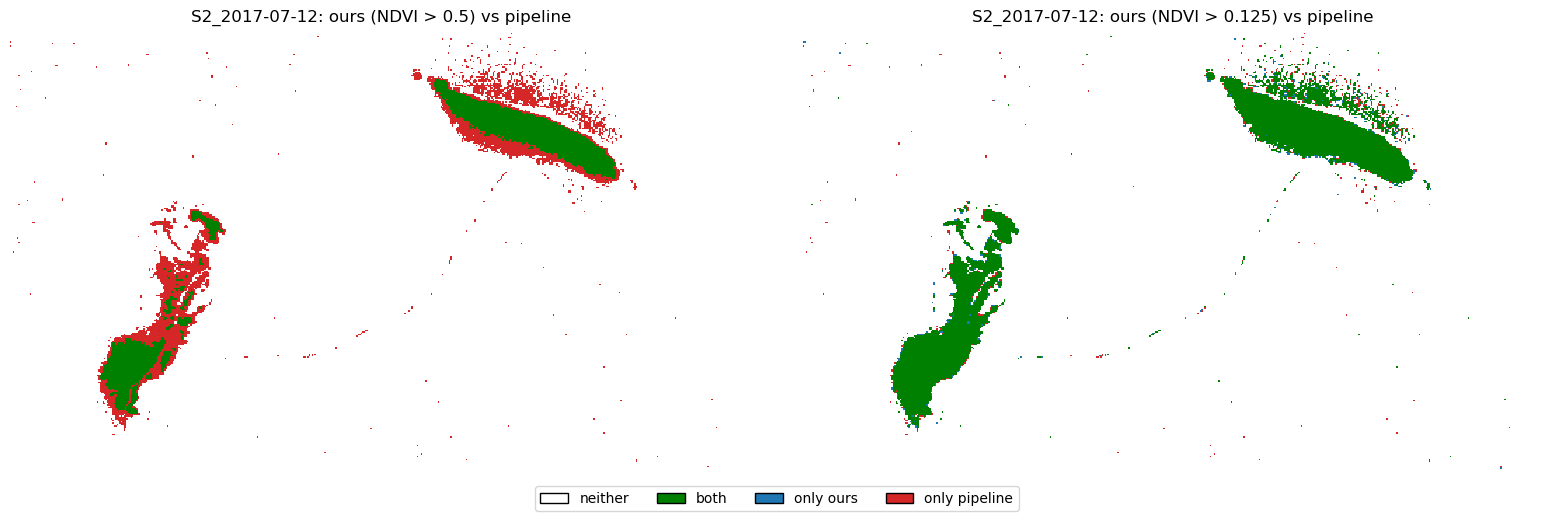

In [19]:
folder = s2_folders[0]
ndvi = ndvi_by_date[folder.name]
theirs = pipeline_masks[folder.name]

# 0 = neither, 1 = both, 2 = only ours, 3 = only the pipeline
classes = ListedColormap(['white', 'green', 'tab:blue', 'tab:red'])
labels = ['neither', 'both', 'only ours', 'only pipeline']

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, threshold in zip(axes, (NDVI_THRESHOLD, PIPELINE_THRESHOLD)):
    mine = vegetation_mask(ndvi, threshold)
    category = np.select([mine & theirs, mine & ~theirs, ~mine & theirs], [1, 2, 3], default=0)
    ax.imshow(category, cmap=classes, vmin=-0.5, vmax=3.5, interpolation='nearest')
    ax.set_title(f'{folder.name}: ours (NDVI > {threshold}) vs pipeline')
    ax.axis('off')
handles = [plt.Rectangle((0, 0), 1, 1, facecolor=classes(i), edgecolor='black') for i in range(4)]
fig.legend(handles, labels, loc='lower center', ncol=4)

plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

We can see that our NDVI threshold of 0.5 was quite strict, as it left out many pixels (red in the left figure) that could also be considered vegetated area. At 0.5, our mask lies almost entirely inside the pipeline's (only 0–2 pixels are vegetation in ours but not in theirs), and our vegetated area is only 45–55% of the pipeline's, with an intersection over union (IoU) of 0.45–0.55. The pixel agreement is still 96–97%, but only because most of the image is sea, which both masks exclude, so the IoU is the more useful measure here.

After lowering our threshold to 0.125, the NDVI at which the pipeline's colour scale turns green, the two masks agree much more closely: the vegetated areas differ by only 1–2% and the IoU rises to about 0.9. The remaining differences go both ways (about 400–550 pixels only in ours and 530–760 only in the pipeline's) and are expected, because the pipeline's colour ramp rounds NDVI into steps, its colour breaks do not exactly match a single threshold, and pixels at the coast are a mix of land and sea.

However, as mentioned in Section 4.2, a threshold of 0.5 is still reasonable, as it is less ambiguous about what counts as "vegetated area" (dense vegetation rather than sparse vegetation or bare ground).

### 5.2. Sensitivity to the NDVI threshold

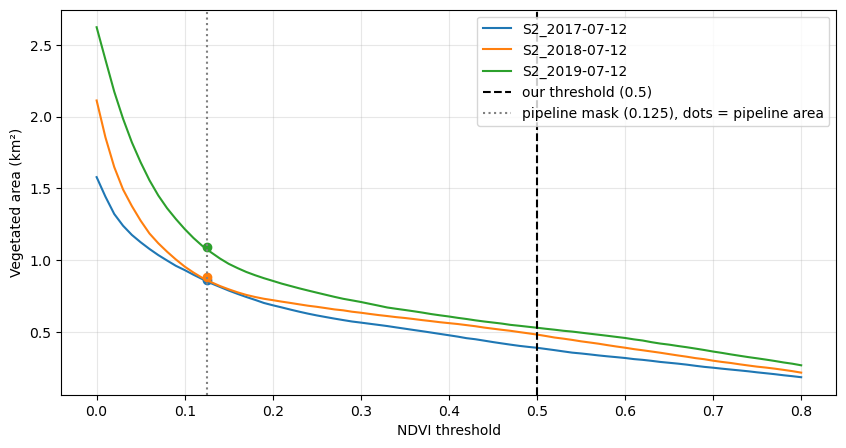

S2_2017-07-12: 1.58 km² at 0, 0.69 km² at 0.2 (-57%), 0.084 km² lost per 0.1 from 0.2 to 0.8, 0.5 -/+ 0.05: +10.2% / -10.2%
S2_2018-07-12: 2.11 km² at 0, 0.72 km² at 0.2 (-66%), 0.084 km² lost per 0.1 from 0.2 to 0.8, 0.5 -/+ 0.05: +8.5% / -9.8%
S2_2019-07-12: 2.62 km² at 0, 0.86 km² at 0.2 (-67%), 0.098 km² lost per 0.1 from 0.2 to 0.8, 0.5 -/+ 0.05: +6.9% / -6.5%


In [20]:
thresholds = np.linspace(0, 0.8, 81)

fig, ax = plt.subplots(figsize=(10, 5))
for name, ndvi in ndvi_by_date.items():
    areas_km2 = [area_from_mask(vegetation_mask(ndvi, t), s2_pixel_area[name]) / 1e6 for t in thresholds]
    line, = ax.plot(thresholds, areas_km2, label=name)
    ax.plot(PIPELINE_THRESHOLD, pipeline_veg_area[name] / 1e6, 'o', color=line.get_color())

ax.axvline(NDVI_THRESHOLD, color='black', ls='--', label=f'our threshold ({NDVI_THRESHOLD})')
ax.axvline(PIPELINE_THRESHOLD, color='grey', ls=':', label=f'pipeline mask ({PIPELINE_THRESHOLD}), dots = pipeline area')
ax.set_xlabel('NDVI threshold')
ax.set_ylabel('Vegetated area (km²)')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

for name, ndvi in ndvi_by_date.items():
    veg_km2 = {t: area_from_mask(vegetation_mask(ndvi, t), s2_pixel_area[name]) / 1e6
               for t in (0, 0.2, 0.8, NDVI_THRESHOLD - 0.05, NDVI_THRESHOLD, NDVI_THRESHOLD + 0.05)}
    print(f"{name}: {veg_km2[0]:.2f} km² at 0, {veg_km2[0.2]:.2f} km² at 0.2 ({veg_km2[0.2] / veg_km2[0] - 1:+.0%}), "
          f"{(veg_km2[0.2] - veg_km2[0.8]) / 6:.3f} km² lost per 0.1 from 0.2 to 0.8, "
          f"{NDVI_THRESHOLD} -/+ 0.05: {veg_km2[NDVI_THRESHOLD - 0.05] / veg_km2[NDVI_THRESHOLD] - 1:+.1%} / "
          f"{veg_km2[NDVI_THRESHOLD + 0.05] / veg_km2[NDVI_THRESHOLD] - 1:+.1%}")

The vegetated area decreases as the NDVI threshold increases, as more pixels fail to meet the criteria. At low thresholds, the vegetated area is very high (1.6–2.6 km² at a threshold of 0), as many pixels of bare rock, sand and ash have NDVI between 0 and 0.2. The area therefore decreases rapidly until the threshold reaches about 0.2, by which point it has dropped by 55–68%. From there, it decreases slowly and almost linearly, by about 0.08–0.1 km² for every 0.1 increase in the threshold. Around our threshold of 0.5, a change of ±0.05 changes the vegetated area by about 7–10%, depending on the date.

The absolute vegetated area therefore depends strongly on the threshold, especially below 0.2. However, the order of the three dates is the same at every threshold (2019 > 2018 > 2017, with 2017 and 2018 almost overlapping around 0.1–0.15), so the increase in vegetated area over time seen in Section 4.4 does not depend on the choice of threshold.

### 5.3. Land area: Sentinel-2 vs Google Earth
An independent land-area estimate from Sentinel-2 uses NDWI = (B03 − B08) / (B03 + B08). Water has NDWI > 0.
These points are plotted together with the Google Earth series from Section 3.5.

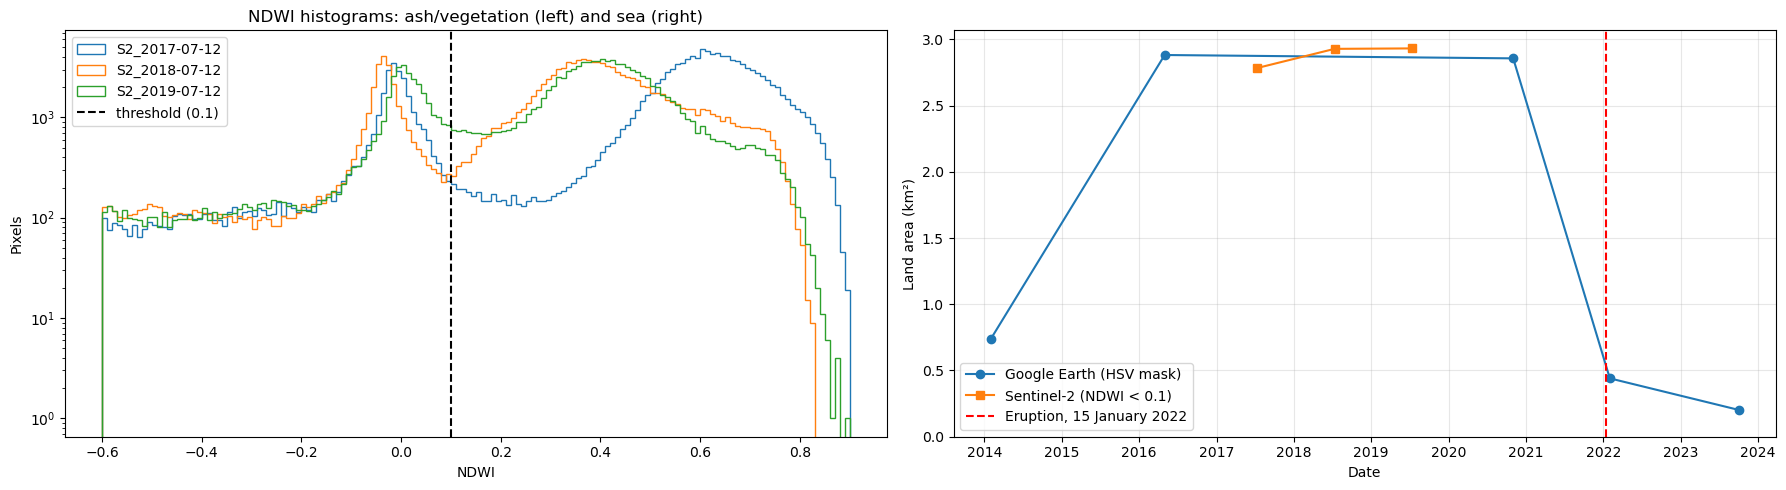

S2_2017-07-12: 2.7836 km² (-3.4% vs Google Earth 2016May, -2.5% vs 2020Nov)
S2_2018-07-12: 2.9282 km² (+1.6% vs Google Earth 2016May, +2.5% vs 2020Nov)
S2_2019-07-12: 2.9315 km² (+1.7% vs Google Earth 2016May, +2.6% vs 2020Nov)
S2_2019-07-12: coastline ≈ 17.6 km, half a pixel (4.68 m) of it ≈ 0.082 km²


In [21]:
# Bare ash has NDWI close to 0, so a threshold of 0 cuts through the cone. The NDWI histogram has
# its minimum between the ash peak (~0) and the sea peak (> 0.3) at about 0.1 on all three dates.
NDWI_THRESHOLD = 0.1
S2_MIN_REGION = 3000   # px; the clouds in 2019 are up to ~2750 px, the island ~32 000 px

s2_land_area = {}   # folder name -> land area in m²

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for folder in s2_folders:
    green, meta = read_band(folder, 'B03_Raw')
    nir, _ = read_band(folder, 'B08_Raw')
    ndwi = normalized_difference(green, nir)
    land = land_mask_ndwi(ndwi, NDWI_THRESHOLD, S2_MIN_REGION)
    s2_land_area[folder.name] = area_from_mask(land, s2_pixel_area[folder.name])
    save_mask(land, out_dir / f"{folder.name}_land_mask.tif", meta['profile'])
    axes[0].hist(ndwi[~np.isnan(ndwi)], bins=150, range=(-0.6, 0.9), histtype='step', log=True, label=folder.name)

axes[0].axvline(NDWI_THRESHOLD, color='black', ls='--', label=f'threshold ({NDWI_THRESHOLD})')
axes[0].set_xlabel('NDWI')
axes[0].set_ylabel('Pixels')
axes[0].set_title('NDWI histograms: ash/vegetation (left) and sea (right)')
axes[0].legend()

ge_names = list(land_area)
axes[1].plot([jpg_dates[name] for name in ge_names],
             [land_area[name] / 1e6 for name in ge_names], 'o-', label='Google Earth (HSV mask)')
axes[1].plot([s2_date(name) for name in s2_land_area], [area / 1e6 for area in s2_land_area.values()],
             's-', label=f'Sentinel-2 (NDWI < {NDWI_THRESHOLD})')
axes[1].axvline(ERUPTION, color='red', ls='--', label='Eruption, 15 January 2022')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Land area (km²)')
axes[1].set_ylim(bottom=0)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

for name, area in s2_land_area.items():
    print(f"{name}: {area / 1e6:.4f} km² ({area / land_area['2016May'] - 1:+.1%} vs Google Earth 2016May, "
          f"{area / land_area['2020Nov'] - 1:+.1%} vs 2020Nov)")

# coastline length from the boundary pixels of the last mask (crater lake shore included),
# and the area change if the coastline moved by half a pixel
coast = land & ~ndimage.binary_erosion(land)
dx, _ = pixel_size_m(meta['res'], meta['bounds'])
coast_m = coast.sum() * dx
print(f"{folder.name}: coastline ≈ {coast_m / 1e3:.1f} km, half a pixel ({dx / 2:.2f} m) of it ≈ "
      f"{coast_m * dx / 2 / 1e6:.3f} km²")


The land areas obtained from the Sentinel-2 images between 2017 and 2019 (2.78–2.93 km²) agree well with the Google Earth results (2.88 km² in May 2016 and 2.86 km² in November 2020), differing by at most about 3%. Although the two data sets were not taken on the same dates, the Sentinel-2 images fall between the two Google Earth images, and together they confirm that the land area remained stable between 2016 and 2020.

They are not identical, and part of the difference is due to the lower resolution of Sentinel-2 (about 9.35 m per pixel, against 1.9 m for Google Earth). Pixels along the coast are a mix of land and sea, and whether they pass the NDWI mask can either overestimate or underestimate the size of the island. The coastline of the Sentinel-2 land mask is about 17.6 km long (counting the boundary pixels, crater lake shore included), so moving it by half a Sentinel-2 pixel (about 4.7 m) changes the area by about 0.08 km², which is the same size as the differences we observe (0.05–0.10 km²). Surf also affects both methods: white water has NDWI close to 0, below our threshold of 0.1, and a hue of 0 in the Google Earth images, so it can be counted as land in both. Finally, the tide at the time each image was taken can move the shoreline by several metres on gently sloping beaches, resulting in a higher or lower land area.

## 6. Final results

In [22]:
rows = []
for name, area in land_area.items():
    rows.append({'source': 'Google Earth', 'quantity': 'land', 'date': jpg_dates[name].date(), 'area_km2': area / 1e6})
for name, area in s2_land_area.items():
    rows.append({'source': 'Sentinel-2', 'quantity': 'land', 'date': s2_date(name).date(), 'area_km2': area / 1e6})
for name, area in veg_area.items():
    rows.append({'source': 'Sentinel-2', 'quantity': 'vegetation', 'date': s2_date(name).date(), 'area_km2': area / 1e6})
for name, area in pipeline_veg_area.items():
    rows.append({'source': 'S2 pipeline', 'quantity': 'vegetation', 'date': s2_date(name).date(), 'area_km2': area / 1e6})

with open(out_dir / 'areas.csv', 'w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=['source', 'quantity', 'date', 'area_km2'])
    writer.writeheader()
    writer.writerows(rows)

print(f"{'source':13} {'quantity':10} {'date':10} {'area (km²)':>10}")
for row in rows:
    print(f"{row['source']:13} {row['quantity']:10} {row['date']!s:10} {row['area_km2']:10.3f}")

source        quantity   date       area (km²)
Google Earth  land       2014-02-01      0.739
Google Earth  land       2016-05-01      2.882
Google Earth  land       2020-11-01      2.856
Google Earth  land       2022-01-31      0.441
Google Earth  land       2023-10-01      0.202
Sentinel-2    land       2017-07-12      2.784
Sentinel-2    land       2018-07-12      2.928
Sentinel-2    land       2019-07-12      2.931
Sentinel-2    vegetation 2017-07-12      0.389
Sentinel-2    vegetation 2018-07-12      0.481
Sentinel-2    vegetation 2019-07-12      0.528
S2 pipeline   vegetation 2017-07-12      0.862
S2 pipeline   vegetation 2018-07-12      0.881
S2 pipeline   vegetation 2019-07-12      1.093


After the 2014-2015 eruption, the land area of the island saw a significant increase from 0.739 km² (2014) to 2.882 km² (2016). Then, it remained stable at around 2.78-2.93 km², with the data from Google Earth and Sentinel-2 agreeing to about 3%. The January 2022 eruption saw a mass reduction in the island's landmass, falling to 0.441 km² in the 2022 image and to 0.202 km² in the October 2023 (2021Dec was excluded because the island was not visible due to an eruption plume).

Over the period in which the land area remained stable, the vegetated area (considered to be above an NDVI of 0.5) increased from 0.389 km² in 2017 to 0.528 km² in 2019. The pipeline gives twice this area because the NDVI threshold is lowered to 0.125. If we lower our own to match the pipeline's, our results are almost identical.

# AI usage

I used Claude (Anthropic, model Claude Opus 5.5) through the Claude Code desktop app on 24, 25 and 26 October 2026. It could read and edit this notebook and run Python in my `ccd_data` environment. On 24 October Claude suggested how to measure the scale bar and wrote the skeleton of the notebook from my outline: the section headings and introductions, the docstrings, the helper functions (`metres_per_pixel`, `jpg_date`, `s2_date`, `read_band`, `pixel_size_m`, `normalized_difference`, `area_from_mask`, `save_mask`) and the cells of Sections 0, 1.2, 2 and 6. On 25 October it turned my hue-threshold snippet into `land_mask_hsv` and added the cleaning steps (opening, small-region removal, hole filling), wrote `remove_small_regions`, `read_ndvi`, `pipeline_vegetation_mask` (the green-channel rule and its NDVI ≈ 0.125 equivalent, which it estimated from our data) and `compare_masks`, helped me complete `vegetation_mask` and `land_mask_ndwi`, and wrote the plotting cells of Sections 3 and 4 and the code of Sections 5 and 6, including the NDWI threshold of 0.1 and the minimum region size. It then reviewed the notebook against the rubric and made the code fixes from that review.

On 26 October Claude checked my markdown explanations and rewrote my drafts of Sections 1.2, 2, 3.1, 3.4, 3.5, 4.2, 4.4, 5.1, 5.2 and 5.3. Besides the language, it corrected parts of my reasoning (the pixel geometry in Section 2, the sea hue in 3.1) and added content: values from the outputs, literature NDVI ranges, and the coastline, surf and tide estimates in 5.3. It suggested a summary for Section 6, which I rewrote in my own words. My unedited drafts are in `ai-unedited-drafts.md`. Claude also explained the EPSG:4326 metadata, the Sentinel-2 bands and the difference between Sentinel-1 and Sentinel-2, reviewed both notebooks before submission, and drafted this statement and the README. Also on 26 October, Claude added code that prints the values quoted in the markdown, in Sections 1.2, 2, 3.5, 4.4, 5.1, 5.2 and 5.3, and corrected the numbers in the markdown of Sections 5.2 and 5.3 to match those printed values.